# 🛰️ Drishti — Explainable Drone-Based Disaster Recognition

**EC-422 Artificial Intelligence · IIT (BHU) Varanasi** — deep learning (transfer learning) on the **AIDER** aerial emergency dataset.

After floods, fires or building collapses, rescue teams need to know *which areas are affected* as fast as possible. A drone photographs the area and this model labels each image as **Collapsed building, Fire/smoke, Flood, Traffic accident or Normal**, shows *where* it looked, and tells the operator when it is not sure.

This single notebook runs the whole pipeline on a Kaggle GPU:

| Step | What happens |
|---|---|
| 1–2 | Download AIDER, decode every image once into a RAM cache, **remove near-duplicate images** (prevents train/test leakage) |
| 3 | Stratified **train / validation / test** split (70 / 15 / 15) — the test set is never used for any decision |
| 4 | Aerial-specific augmentation (flips + 90° rotations, zoom, lighting, blur, occlusion) |
| 5–6 | Fine-tune **two ImageNet-pretrained backbones** — MobileNetV3-Large (drone/edge) and EfficientNet-B0 (accuracy) — with imbalance-aware loss, mixed precision and two-stage training |
| 7 | Held-out test evaluation: accuracy, **macro-F1**, confusion matrix, test-time augmentation |
| 8 | **Confidence calibration** (temperature scaling) + human-in-the-loop threshold |
| 9 | **Grad-CAM** heatmaps: where is the fire / flood / rubble? |
| 10 | **Area-scan mode**: tile a large drone image and map where each disaster is |
| 11 | Edge readiness: model size and CPU latency |
| 12 | Export the model, figures and metrics for the Gradio app |

**Before you run (Kaggle):** *Settings → Accelerator → **GPU T4 x2*** and *Settings → Internet → **On***. Then **Run All** (≈ 20–30 min).
Set `QUICK_RUN = True` in the config cell for a 3-minute dry run first.

## 1 · Setup

In [1]:
import os, sys, io, json, math, time, copy, random, hashlib, shutil, zipfile, urllib.request, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
ON_KAGGLE = os.path.isdir("/kaggle/working")
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | "
      f"torchvision {torchvision.__version__} | running on Kaggle: {ON_KAGGLE}")


def pick_device():
    """Use the GPU only if this PyTorch build can really run kernels on it (Kaggle's P100 is no longer supported)."""
    if not torch.cuda.is_available():
        print("⚠️  No GPU detected - training will be slow. On Kaggle: Settings > Accelerator > GPU T4 x2.")
        return torch.device("cpu")
    name = torch.cuda.get_device_name(0)
    try:
        a = torch.randn(1, 3, 16, 16, device="cuda")
        F.conv2d(a, torch.randn(4, 3, 3, 3, device="cuda"))
        torch.cuda.synchronize()
    except RuntimeError as err:
        raise RuntimeError(f"PyTorch {torch.__version__} cannot run on '{name}' ({err}).\n"
                           "On Kaggle switch Settings > Accelerator > GPU T4 x2, then restart and run all.") from err
    print(f"✅ GPU ready: {name}")
    return torch.device("cuda")


DEVICE = pick_device()

Python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | running on Kaggle: True
✅ GPU ready: Tesla T4


In [2]:
# ================================ CONFIG ================================
QUICK_RUN = False   # True -> ~3 min dry run on a small subset (run it once to check everything works)

CFG = dict(
    seed=42,
    cache_size=256,              # every image is decoded once and kept in RAM at 256 x 256
    img_size=224,                # network input size
    batch_size=32,
    backbones=["mobilenet_v3_large", "efficientnet_b0"],   # edge model vs. accuracy model
    pretrained=True,             # ImageNet weights (needs Internet ON in Kaggle settings)
    head_epochs=3,               # stage 1: backbone frozen, only the new classifier head learns
    finetune_epochs=15,          # stage 2: everything unfrozen, small learning rate
    lr_head=1e-3,
    lr_finetune=3e-4,
    weight_decay=1e-4,
    label_smoothing=0.1,
    patience=5,                  # early stopping on validation macro-F1
    val_size=0.15,
    test_size=0.15,
    uncertainty_threshold=0.60,  # calibrated confidence below this -> "send to a human analyst"
    num_workers=min(4, os.cpu_count() or 1),
)
if QUICK_RUN:
    CFG.update(head_epochs=1, finetune_epochs=1, patience=1)
if sys.platform != "linux":
    CFG["num_workers"] = 0       # DataLoader worker processes inside notebooks are only reliable on Linux

WORK_DIR = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()
DATA_DIR = Path("/tmp/aider") if ON_KAGGLE else Path.cwd() / "data"   # raw data stays out of the saved output
OUT_DIR = WORK_DIR / "drishti_outputs"
FIG_DIR = OUT_DIR / "figures"
for d in (DATA_DIR, OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True    # fixed input size -> let cuDNN pick the fastest kernels


def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()


seed_everything(CFG["seed"])
print(json.dumps(CFG, indent=1))

{
 "seed": 42,
 "cache_size": 256,
 "img_size": 224,
 "batch_size": 32,
 "backbones": [
  "mobilenet_v3_large",
  "efficientnet_b0"
 ],
 "pretrained": true,
 "head_epochs": 3,
 "finetune_epochs": 15,
 "lr_head": 0.001,
 "lr_finetune": 0.0003,
 "weight_decay": 0.0001,
 "label_smoothing": 0.1,
 "patience": 5,
 "val_size": 0.15,
 "test_size": 0.15,
 "uncertainty_threshold": 0.6,
 "num_workers": 4
}


## 2 · Get the AIDER dataset

**AIDER** (*Aerial Image Database for Emergency Response*, Kyrkou & Theocharides, CVPRW 2019 / IEEE JSTARS 2020) — the public subset has 5 classes: about 500 images for each disaster class and 4,000+ *normal* images, so it is **heavily imbalanced** (a model that always answers "normal" is already right about two times out of three — that is why we report **macro-F1**, the unweighted average of the per-class F1 scores).

The cell below uses, in this order: a copy attached to the notebook (*+ Add Input*), a previous download, or a fresh download from Zenodo ([DOI 10.5281/zenodo.3888300](https://doi.org/10.5281/zenodo.3888300), CC BY 4.0, checksum verified).
If Zenodo is slow, download `AIDER.zip` yourself, upload it as a private Kaggle dataset, attach it with *+ Add Input* and re-run — it is found automatically.

In [3]:
CLASSES = ["collapsed_building", "fire", "flooded_areas", "normal", "traffic_incident"]   # AIDER folder names
DISPLAY = {"collapsed_building": "Collapsed building", "fire": "Fire / smoke", "flooded_areas": "Flood",
           "normal": "Normal", "traffic_incident": "Traffic accident"}
CLASS_COLORS = {"collapsed_building": "#8d6e63", "fire": "#e4572e", "flooded_areas": "#2e86de",
                "normal": "#43a047", "traffic_incident": "#f2a900"}
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
ZENODO_URL = "https://zenodo.org/records/3888300/files/AIDER.zip?download=1"
ZENODO_MD5 = "1ad4eb02ed156e8dfa19986ff382e58b"


KEYWORDS = {"collapsed_building": ("collapse", "rubble"), "fire": ("fire", "smoke"), "flooded_areas": ("flood",),
            "normal": ("normal",), "traffic_incident": ("traffic", "accident", "incident")}


def canonical(folder_name):
    """Map a folder name such as 'flooded_areas' or 'Flood' to one of the five class ids."""
    name = folder_name.lower()
    return next((c for c, keys in KEYWORDS.items() if any(k in name for k in keys)), None)


def find_aider_root(base):
    """Return the folder that contains all five AIDER class folders (searched recursively)."""
    base = Path(base)
    if not base.is_dir():
        return None
    for root, dirs, _ in os.walk(base):
        if "__MACOSX" in root:
            continue
        if {canonical(d) for d in dirs} >= set(CLASSES):
            return Path(root)
    return None


def md5sum(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


def download(url, dst, retries=3):
    for attempt in range(1, retries + 1):
        try:
            print(f"Downloading AIDER.zip from Zenodo (attempt {attempt}) ...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=60) as r, open(dst, "wb") as f:
                total, done, mark = int(r.headers.get("Content-Length", 0)), 0, 0.1
                while chunk := r.read(1 << 20):
                    f.write(chunk)
                    done += len(chunk)
                    if total and done / total >= mark:
                        print(f"   {done / 1e6:5.0f} / {total / 1e6:.0f} MB")
                        mark += 0.1
            return
        except Exception as err:
            print("   failed:", err)
            time.sleep(5 * attempt)
    raise RuntimeError("Download failed. Turn Internet ON in the Kaggle settings, or upload AIDER.zip as a "
                       "Kaggle dataset (+ Add Input) and run this cell again.")


def get_aider():
    # 1) already there: dataset attached with "+ Add Input", or extracted by a previous run
    for base in (Path("/kaggle/input"), DATA_DIR):
        root = find_aider_root(base)
        if root:
            return root
    # 2) a zip attached as input, otherwise 3) download from Zenodo
    zips = sorted(Path("/kaggle/input").rglob("*.zip")) if Path("/kaggle/input").is_dir() else []
    zip_path = next((z for z in zips if "aider" in z.name.lower()), None)
    if zip_path is None:
        zip_path = DATA_DIR / "AIDER.zip"
        if not (zip_path.exists() and md5sum(zip_path) == ZENODO_MD5):
            download(ZENODO_URL, zip_path)
            if md5sum(zip_path) != ZENODO_MD5:
                print("⚠️  MD5 checksum differs from the one published on Zenodo - the file may be incomplete.")
    print("Extracting", zip_path.name, "...")
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(DATA_DIR)
    root = find_aider_root(DATA_DIR)
    if root is None:
        raise RuntimeError(f"Could not find the five AIDER class folders inside {zip_path}")
    return root

DATA_DIR = Path("/kaggle/input/datasets/gauravsrc/aider-dataset/AIDER")
AIDER_ROOT = get_aider()
print("AIDER folder:", AIDER_ROOT)

folders = {canonical(d.name): d for d in sorted(AIDER_ROOT.iterdir()) if d.is_dir() and canonical(d.name)}
print({c: folders[c].name for c in CLASSES})
records = [(str(p), c, i)
           for i, c in enumerate(CLASSES)
           for p in sorted(folders[c].rglob("*"))
           if p.is_file() and p.suffix.lower() in IMG_EXTS and not p.name.startswith(".")]
df = pd.DataFrame(records, columns=["path", "label", "y"])
if QUICK_RUN:   # small subset that keeps the class imbalance
    parts = [g.sample(min(len(g), 80 if c == "normal" else 40), random_state=CFG["seed"])
             for c, g in df.groupby("label")]
    df = pd.concat(parts).sort_values("path").reset_index(drop=True)
print(f"\n{len(df)} image files")
print(df.label.map(DISPLAY).value_counts().to_string())

AIDER folder: /kaggle/input/datasets/gauravsrc/aider-dataset/AIDER
{'collapsed_building': 'collapsed_building', 'fire': 'fire', 'flooded_areas': 'flooded_areas', 'normal': 'normal', 'traffic_incident': 'traffic_incident'}

6433 image files
label
Normal                4390
Flood                  526
Fire / smoke           521
Collapsed building     511
Traffic accident       485


### Decode once, cache in RAM, remove near-duplicates

Web-collected datasets often contain the same photo twice (re-uploaded, resized or re-compressed). If one copy lands in *train* and the other in *test*, the test score is inflated. Every image gets a 64-bit perceptual **difference hash**; copies with the same hash and label are dropped, and copies that appear under *different* labels are removed as ambiguous.

In [4]:
S = CFG["cache_size"]


def dhash(arr, size=8):
    """64-bit difference hash: resized or re-encoded copies of the same photo get the same hash."""
    g = Image.fromarray(arr).convert("L").resize((size + 1, size), Image.Resampling.BILINEAR)
    g = np.asarray(g, dtype=np.int16)
    return np.packbits(g[:, 1:] > g[:, :-1]).tobytes().hex()


def decode(path):
    try:
        with Image.open(path) as im:
            im.draft("RGB", (S, S))                          # JPEG fast path: decode at reduced resolution
            im = ImageOps.exif_transpose(im).convert("RGB")
            arr = np.asarray(im.resize((S, S), Image.Resampling.BILINEAR), dtype=np.uint8)
        return arr, dhash(arr)
    except Exception:
        return None, None


t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
    decoded = list(pool.map(decode, df.path))
df["dhash"] = [h for _, h in decoded]
bad = df.dhash.isna()

# same hash + same class -> keep one copy; same hash + different classes -> drop all copies (ambiguous label)
n_labels = df.loc[~bad].groupby("dhash").label.transform("nunique")
conflict = pd.Series(False, index=df.index)
conflict.loc[n_labels.index] = (n_labels > 1).to_numpy()
duplicate = ~bad & ~conflict & df.duplicated("dhash")
keep = ~(bad | conflict | duplicate)

IMAGES = np.stack([decoded[i][0] for i in np.flatnonzero(keep.to_numpy())])
del decoded
df = df.loc[keep].reset_index(drop=True)
LABELS = df.y.to_numpy()
CLEANING = dict(files_found=int(len(keep)), unreadable=int(bad.sum()), near_duplicates_removed=int(duplicate.sum()),
                label_conflicts_removed=int(conflict.sum()), images_kept=int(len(df)))
print(f"Decoded and hashed in {time.time() - t0:.0f}s | RAM cache {IMAGES.nbytes / 1e9:.2f} GB")
print(CLEANING)

Decoded and hashed in 21s | RAM cache 1.26 GB
{'files_found': 6433, 'unreadable': 0, 'near_duplicates_removed': 33, 'label_conflicts_removed': 4, 'images_kept': 6396}


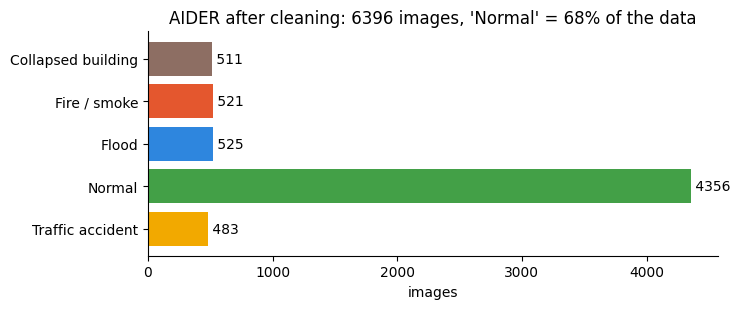

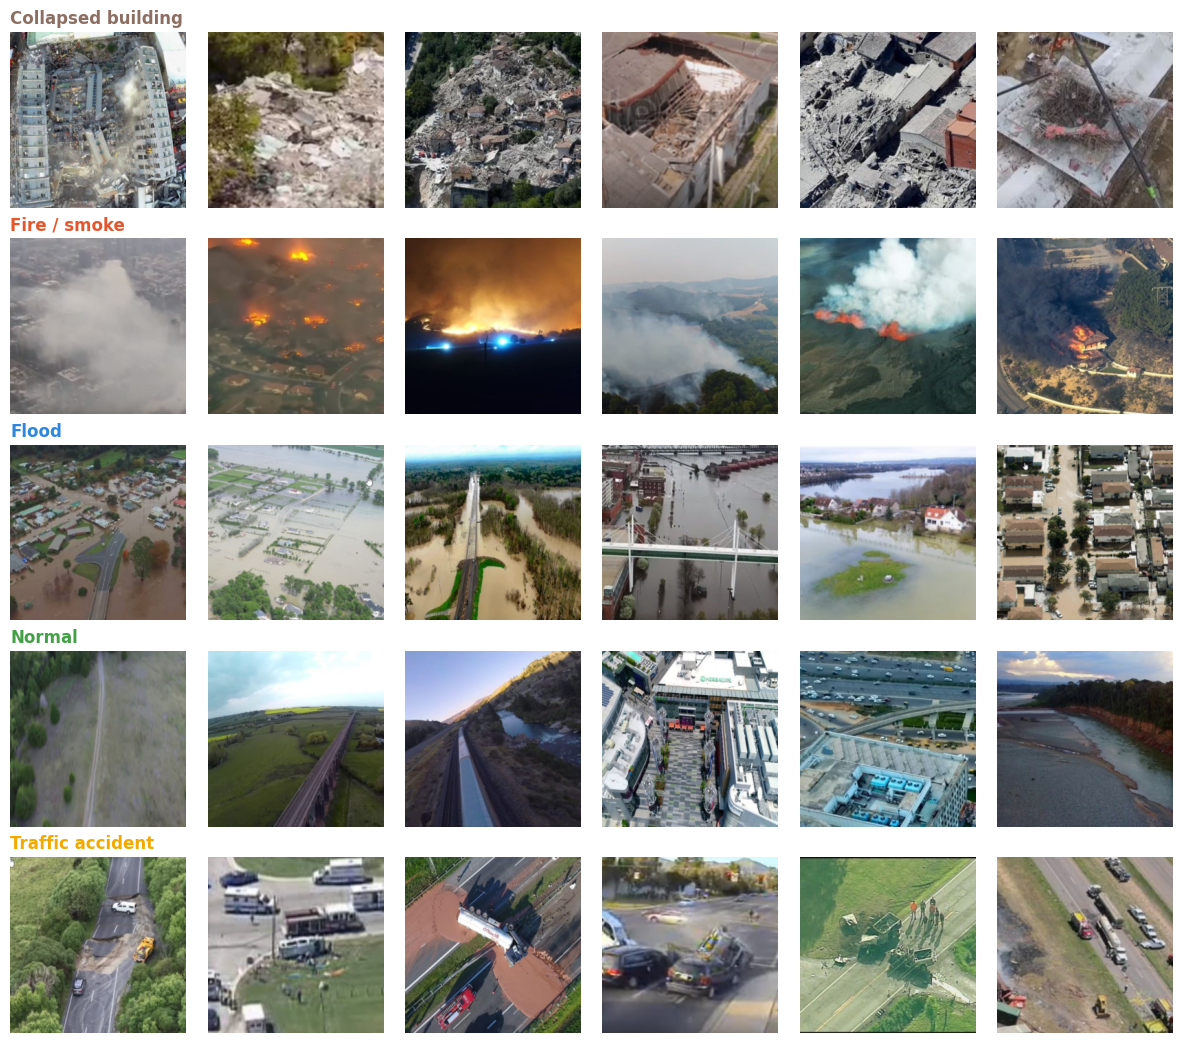

In [5]:
counts = df.label.value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh([DISPLAY[c] for c in CLASSES], counts.values, color=[CLASS_COLORS[c] for c in CLASSES])
for i, v in enumerate(counts.values):
    ax.text(v, i, f" {v}", va="center")
ax.invert_yaxis()
ax.set_xlabel("images")
ax.set_title(f"AIDER after cleaning: {len(df)} images, 'Normal' = {counts['normal'] / len(df):.0%} of the data")
save_fig("class_distribution.png")

rng = np.random.default_rng(CFG["seed"])
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(12, 10.5))
for r, c in enumerate(CLASSES):
    members = np.flatnonzero(LABELS == r)
    for k, j in enumerate(rng.choice(members, size=min(6, len(members)), replace=False)):
        axes[r, k].imshow(IMAGES[j])
    for ax in axes[r]:
        ax.axis("off")
    axes[r, 0].set_title(DISPLAY[c], loc="left", fontsize=12, color=CLASS_COLORS[c], fontweight="bold")
save_fig("samples.png")

## 3 · Stratified train / validation / test split

70 / 15 / 15, stratified so every split keeps the class ratios. **Validation** is used for early stopping, model selection and calibration; the **test** set is only used for the final numbers.
The loss uses *square-root inverse-frequency* class weights so the rare disaster classes are not drowned out by *normal* images.

In [6]:
idx = np.arange(len(df))
idx_trainval, idx_test = train_test_split(idx, test_size=CFG["test_size"], stratify=LABELS,
                                          random_state=CFG["seed"])
idx_train, idx_val = train_test_split(idx_trainval, test_size=CFG["val_size"] / (1 - CFG["test_size"]),
                                      stratify=LABELS[idx_trainval], random_state=CFG["seed"])
df["split"] = "train"
df.loc[idx_val, "split"] = "val"
df.loc[idx_test, "split"] = "test"
(df.assign(file=df.path.map(lambda p: os.path.relpath(p, AIDER_ROOT)))[["file", "label", "split"]]
   .to_csv(OUT_DIR / "splits.csv", index=False))
print(pd.crosstab(df.label.map(DISPLAY), df.split)[["train", "val", "test"]], "\n")

train_counts = np.bincount(LABELS[idx_train], minlength=len(CLASSES))
w = (train_counts.sum() / (len(CLASSES) * train_counts)) ** 0.5      # sqrt inverse-frequency
CLASS_WEIGHTS = torch.tensor(w / w.mean(), dtype=torch.float32)
print("loss weights:", {DISPLAY[c]: round(float(x), 2) for c, x in zip(CLASSES, CLASS_WEIGHTS)})

split               train  val  test
label                               
Collapsed building    357   77    77
Fire / smoke          365   78    78
Flood                 367   79    79
Normal               3048  654   654
Traffic accident      339   72    72 

loss weights: {'Collapsed building': 1.15, 'Fire / smoke': 1.14, 'Flood': 1.14, 'Normal': 0.39, 'Traffic accident': 1.18}


## 4 · Aerial-specific augmentation and data loaders

A drone looking straight down has no "up" direction, so **horizontal/vertical flips and 90° rotations** never change the label. Random zoom-crops mimic different flight altitudes, colour jitter and blur mimic weather, haze and motion, and random erasing mimics partial occlusion (smoke, trees, clouds).

139 training batches / epoch, 30 validation batches


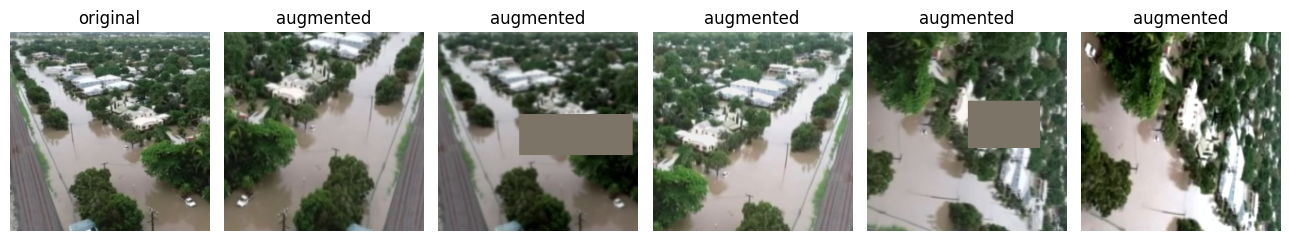

In [7]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet statistics (pretrained backbones)
SZ = CFG["img_size"]


class RandomRot90:
    """Label-preserving 0/90/180/270-degree rotation for top-down images."""
    def __call__(self, img):
        k = random.randint(0, 3)
        return img.rotate(90 * k) if k else img


train_tf = T.Compose([
    T.RandomResizedCrop(SZ, scale=(0.5, 1.0), ratio=(0.8, 1.25)),     # altitude / zoom changes
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(), RandomRot90(),    # drone heading changes
    T.RandomApply([T.ColorJitter(0.3, 0.3, 0.3, 0.03)], p=0.8),         # light, haze, camera differences
    T.RandomGrayscale(p=0.05),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.2),        # motion / focus blur
    T.ToTensor(),
    T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.25, scale=(0.02, 0.12)),                        # partial occlusion
])
eval_tf = T.Compose([T.Resize((SZ, SZ)), T.ToTensor(), T.Normalize(MEAN, STD)])


class CachedImages(Dataset):
    def __init__(self, indices, transform):
        self.indices, self.transform = np.asarray(indices), transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        return self.transform(Image.fromarray(IMAGES[j])), int(LABELS[j])


def make_loader(indices, transform, train=False, batch_size=None):
    return DataLoader(CachedImages(indices, transform), batch_size=batch_size or CFG["batch_size"],
                      shuffle=train, drop_last=train, num_workers=CFG["num_workers"],
                      pin_memory=DEVICE.type == "cuda", persistent_workers=train and CFG["num_workers"] > 0)


train_loader = make_loader(idx_train, train_tf, train=True)
val_loader = make_loader(idx_val, eval_tf)
print(f"{len(train_loader)} training batches / epoch, {len(val_loader)} validation batches")

# what the network actually sees during training
j = idx_train[np.flatnonzero(LABELS[idx_train] != CLASSES.index("normal"))[0]]
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
axes[0].imshow(IMAGES[j])
axes[0].set_title("original")
for ax in axes[1:]:
    x = train_tf(Image.fromarray(IMAGES[j])).permute(1, 2, 0).numpy() * STD + MEAN
    ax.imshow(np.clip(x, 0, 1))
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
save_fig("augmentations.png")

## 5 · Models: two ImageNet-pretrained backbones

Training from scratch on ~6 k images needs hundreds of epochs (the original EmergencyNet recipe trains for 200). **Transfer learning** re-uses features learned on 1.2 M ImageNet photos and converges in minutes on a free GPU.

| Backbone | Why |
|---|---|
| `mobilenet_v3_large` | designed for phones/drones — fast on CPU, small |
| `efficientnet_b0` | best accuracy per FLOP in its size class |

Only the last layer is replaced by a new 5-class layer.

In [8]:
def build_model(arch, num_classes=len(CLASSES), pretrained=True):
    """torchvision backbone (optionally ImageNet-pretrained) with a new num_classes-way output layer."""
    if not arch.startswith(("efficientnet", "mobilenet_v3")):
        raise ValueError("This notebook supports efficientnet_* and mobilenet_v3_* backbones")
    try:
        model = torchvision.models.get_model(arch, weights="DEFAULT" if pretrained else None)
    except Exception as err:
        raise RuntimeError("Could not download the ImageNet weights - turn Internet ON in Kaggle settings.") from err
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    return model


def count_params(model):
    return sum(p.numel() for p in model.parameters()) / 1e6


for arch in CFG["backbones"]:
    print(f"{arch:20s} {count_params(build_model(arch, pretrained=False)):.2f} M parameters")

mobilenet_v3_large   4.21 M parameters
efficientnet_b0      4.01 M parameters


## 6 · Two-stage fine-tuning with mixed precision

* **Stage 1 (head):** backbone frozen (BatchNorm statistics kept), only the new layer learns → the random head cannot destroy the pretrained features.
* **Stage 2 (fine-tune):** everything unfrozen, smaller learning rate with linear warm-up + cosine decay.
* Weighted cross-entropy + label smoothing, AdamW, **AMP float16** on the GPU, early stopping on **validation macro-F1** and the best checkpoint is restored.

In [9]:
AMP = DEVICE.type == "cuda"


def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None, frozen_backbone=False):
    training = optimizer is not None
    model.train(training)
    if training and frozen_backbone:
        model.features.eval()              # keep the pretrained BatchNorm statistics while only the head learns
    loss_sum, all_logits, all_y = 0.0, [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(training), torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            logits = model(x)
            loss = criterion(logits, y)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
        loss_sum += loss.item() * len(y)
        all_logits.append(logits.detach().float().cpu())
        all_y.append(y.cpu())
    logits, ys = torch.cat(all_logits), torch.cat(all_y)
    preds = logits.argmax(1)
    return dict(loss=loss_sum / len(ys), acc=(preds == ys).float().mean().item(),
                f1=f1_score(ys, preds, average="macro", zero_division=0))


def train_model(arch):
    seed_everything(CFG["seed"])
    model = build_model(arch, pretrained=CFG["pretrained"]).to(DEVICE).to(memory_format=torch.channels_last)
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE), label_smoothing=CFG["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    history, best_f1, best_state, epoch = [], -1.0, None, 0
    for stage, n_epochs, lr in [("head", CFG["head_epochs"], CFG["lr_head"]),
                                ("finetune", CFG["finetune_epochs"], CFG["lr_finetune"])]:
        if n_epochs == 0:
            continue
        for p in model.features.parameters():
            p.requires_grad = stage == "finetune"
        optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                      lr=lr, weight_decay=CFG["weight_decay"])
        total = n_epochs * len(train_loader)
        warmup = max(1, int(0.1 * total))          # linear warm-up, then cosine decay to 2 % of lr

        def lr_factor(step, total=total, warmup=warmup):
            if step < warmup:
                return (step + 1) / warmup
            return 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total - warmup)))

        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
        stale = 0
        for _ in range(n_epochs):
            epoch += 1
            t0 = time.time()
            tr = run_epoch(model, train_loader, criterion, optimizer, scheduler, scaler,
                           frozen_backbone=stage == "head")
            va = run_epoch(model, val_loader, criterion)
            history.append(dict(epoch=epoch, stage=stage, train_loss=tr["loss"], train_acc=tr["acc"],
                                train_f1=tr["f1"], val_loss=va["loss"], val_acc=va["acc"], val_f1=va["f1"],
                                seconds=time.time() - t0))
            improved = va["f1"] > best_f1 + 1e-4
            if improved:
                best_f1, stale = va["f1"], 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                stale += 1
            print(f"[{arch}] ep {epoch:2d} {stage:8s} | train loss {tr['loss']:.3f} acc {tr['acc']:.3f} | "
                  f"val loss {va['loss']:.3f} acc {va['acc']:.3f} macro-F1 {va['f1']:.3f}"
                  f"{' *' if improved else '  '} | {time.time() - t0:.0f}s")
            if stage == "finetune" and stale >= CFG["patience"]:
                print(f"[{arch}] early stop: no validation macro-F1 gain for {stale} epochs")
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_f1

In [10]:
RESULTS = {}
for arch in CFG["backbones"]:
    t0 = time.time()
    model, history, best_val_f1 = train_model(arch)
    history.to_csv(OUT_DIR / f"history_{arch}.csv", index=False)
    RESULTS[arch] = dict(model=model, history=history, best_val_f1=best_val_f1,
                         train_minutes=(time.time() - t0) / 60)
    print(f"==> {arch}: best validation macro-F1 {best_val_f1:.4f} "
          f"({RESULTS[arch]['train_minutes']:.1f} min)\n")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 145MB/s] 


[mobilenet_v3_large] ep  1 head     | train loss 0.959 acc 0.850 | val loss 0.787 acc 0.931 macro-F1 0.898 * | 21s
[mobilenet_v3_large] ep  2 head     | train loss 0.781 acc 0.931 | val loss 0.750 acc 0.955 macro-F1 0.927 * | 15s
[mobilenet_v3_large] ep  3 head     | train loss 0.747 acc 0.949 | val loss 0.735 acc 0.952 macro-F1 0.924   | 14s
[mobilenet_v3_large] ep  4 finetune | train loss 0.840 acc 0.911 | val loss 0.715 acc 0.954 macro-F1 0.928 * | 35s
[mobilenet_v3_large] ep  5 finetune | train loss 0.733 acc 0.946 | val loss 0.738 acc 0.957 macro-F1 0.921   | 16s
[mobilenet_v3_large] ep  6 finetune | train loss 0.692 acc 0.964 | val loss 0.674 acc 0.977 macro-F1 0.963 * | 16s
[mobilenet_v3_large] ep  7 finetune | train loss 0.662 acc 0.973 | val loss 0.660 acc 0.974 macro-F1 0.953   | 16s
[mobilenet_v3_large] ep  8 finetune | train loss 0.644 acc 0.982 | val loss 0.651 acc 0.976 macro-F1 0.959   | 16s
[mobilenet_v3_large] ep  9 finetune | train loss 0.640 acc 0.983 | val loss 0.67

100%|██████████| 20.5M/20.5M [00:00<00:00, 144MB/s] 


[efficientnet_b0] ep  1 head     | train loss 1.138 acc 0.744 | val loss 0.839 acc 0.903 macro-F1 0.869 * | 16s
[efficientnet_b0] ep  2 head     | train loss 0.869 acc 0.877 | val loss 0.809 acc 0.908 macro-F1 0.872 * | 15s
[efficientnet_b0] ep  3 head     | train loss 0.844 acc 0.892 | val loss 0.804 acc 0.917 macro-F1 0.882 * | 15s
[efficientnet_b0] ep  4 finetune | train loss 0.933 acc 0.850 | val loss 0.748 acc 0.940 macro-F1 0.906 * | 27s
[efficientnet_b0] ep  5 finetune | train loss 0.800 acc 0.913 | val loss 0.701 acc 0.958 macro-F1 0.935 * | 17s
[efficientnet_b0] ep  6 finetune | train loss 0.722 acc 0.951 | val loss 0.685 acc 0.968 macro-F1 0.947 * | 17s
[efficientnet_b0] ep  7 finetune | train loss 0.707 acc 0.960 | val loss 0.672 acc 0.975 macro-F1 0.957 * | 17s
[efficientnet_b0] ep  8 finetune | train loss 0.680 acc 0.967 | val loss 0.668 acc 0.979 macro-F1 0.963 * | 17s
[efficientnet_b0] ep  9 finetune | train loss 0.666 acc 0.975 | val loss 0.662 acc 0.978 macro-F1 0.962 

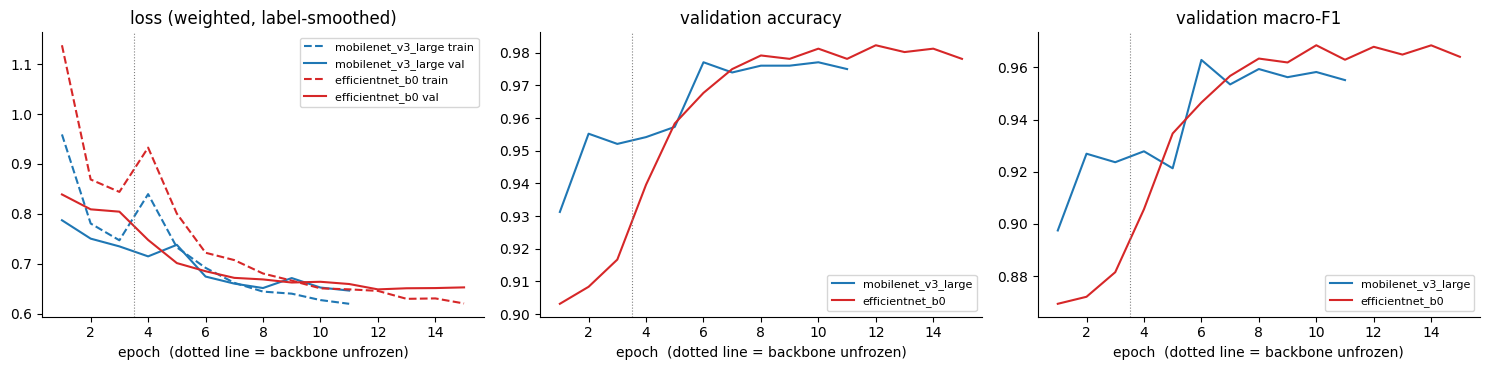

In [11]:
palette = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for (arch, R), col in zip(RESULTS.items(), palette):
    h = R["history"]
    axes[0].plot(h.epoch, h.train_loss, "--", color=col, label=f"{arch} train")
    axes[0].plot(h.epoch, h.val_loss, color=col, label=f"{arch} val")
    axes[1].plot(h.epoch, h.val_acc, color=col, label=arch)
    axes[2].plot(h.epoch, h.val_f1, color=col, label=arch)
for ax, title in zip(axes, ["loss (weighted, label-smoothed)", "validation accuracy", "validation macro-F1"]):
    ax.axvline(CFG["head_epochs"] + 0.5, color="gray", lw=0.8, ls=":")
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.set_title(title)
    ax.set_xlabel("epoch  (dotted line = backbone unfrozen)")
    ax.legend(fontsize=8)
save_fig("training_curves.png")

## 7 · Held-out test evaluation

The deployed model is chosen by **validation** macro-F1 — never by the test set. *TTA* (test-time augmentation) averages predictions over the original, two flips and a 90° rotation, which is valid for top-down images.

In [12]:
@torch.no_grad()
def predict_logits(model, indices, tta=False):
    model.eval()
    out = []
    for x, _ in make_loader(indices, eval_tf, batch_size=64):
        x = x.to(DEVICE).to(memory_format=torch.channels_last)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            if tta:
                views = [x, x.flip(3), x.flip(2), x.rot90(1, (2, 3))]
                probs = torch.stack([model(v).float().softmax(1) for v in views]).mean(0)
                logits = probs.clamp_min(1e-8).log()
            else:
                logits = model(x)
        out.append(logits.float().cpu())
    return torch.cat(out)


def scores(y, logits):
    p = logits.argmax(1)
    return dict(acc=accuracy_score(y, p), macro_f1=f1_score(y, p, average="macro"),
                weighted_f1=f1_score(y, p, average="weighted"))


y_val, y_test = torch.as_tensor(LABELS[idx_val]), torch.as_tensor(LABELS[idx_test])
rows = []
for arch, R in RESULTS.items():
    R["val_logits"] = predict_logits(R["model"], idx_val)
    R["test_logits"] = predict_logits(R["model"], idx_test)
    R["test"] = scores(y_test, R["test_logits"])
    R["test_tta"] = scores(y_test, predict_logits(R["model"], idx_test, tta=True))
    rows.append({"model": arch, "val macro-F1": R["best_val_f1"], "test accuracy": R["test"]["acc"],
                 "test macro-F1": R["test"]["macro_f1"], "test macro-F1 (TTA)": R["test_tta"]["macro_f1"]})
print(pd.DataFrame(rows).round(4).to_string(index=False))

BEST = max(RESULTS, key=lambda a: RESULTS[a]["best_val_f1"])     # chosen on validation, never on test
best_model = RESULTS[BEST]["model"]
test_logits = RESULTS[BEST]["test_logits"]
test_pred = test_logits.argmax(1).numpy()
print(f"\nSelected for deployment (best validation macro-F1): {BEST}\n")
report_txt = classification_report(y_test, test_pred, target_names=[DISPLAY[c] for c in CLASSES], digits=3,
                                   zero_division=0)
print(report_txt)
REPORT = classification_report(y_test, test_pred, target_names=CLASSES, output_dict=True, zero_division=0)
with open(OUT_DIR / "classification_report.txt", "w") as f:
    f.write(f"Model: {BEST}\n\n{report_txt}")

             model  val macro-F1  test accuracy  test macro-F1  test macro-F1 (TTA)
mobilenet_v3_large        0.9628         0.9792         0.9679               0.9640
   efficientnet_b0        0.9685         0.9792         0.9611               0.9566

Selected for deployment (best validation macro-F1): efficientnet_b0

                    precision    recall  f1-score   support

Collapsed building      0.973     0.948     0.961        77
      Fire / smoke      0.987     0.949     0.967        78
             Flood      1.000     0.949     0.974        79
            Normal      0.988     0.994     0.991       654
  Traffic accident      0.883     0.944     0.913        72

          accuracy                          0.979       960
         macro avg      0.966     0.957     0.961       960
      weighted avg      0.980     0.979     0.979       960



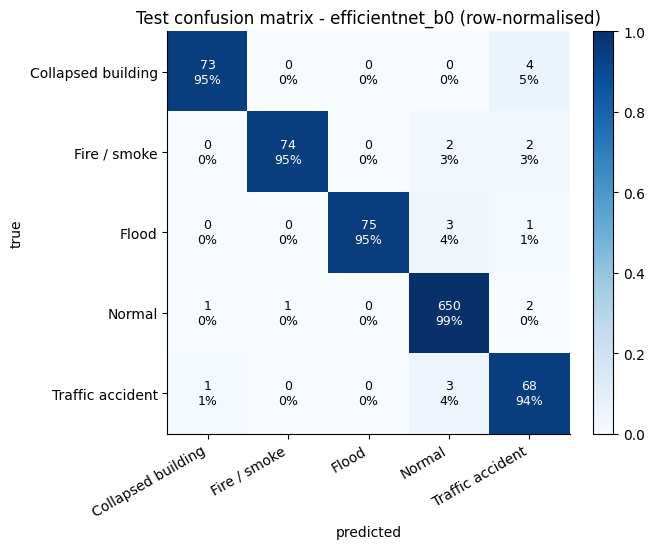

In [13]:
cm = confusion_matrix(y_test, test_pred, labels=list(range(len(CLASSES))))
cm_norm = cm / cm.sum(1, keepdims=True)
names = [DISPLAY[c] for c in CLASSES]
fig, ax = plt.subplots(figsize=(6.6, 5.6))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for k in range(len(CLASSES)):
        ax.text(k, i, f"{cm[i, k]}\n{cm_norm[i, k]:.0%}", ha="center", va="center", fontsize=9,
                color="white" if cm_norm[i, k] > 0.5 else "black")
ax.set_xticks(range(len(CLASSES)), names, rotation=30, ha="right")
ax.set_yticks(range(len(CLASSES)), names)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f"Test confusion matrix - {BEST} (row-normalised)")
fig.colorbar(im, fraction=0.046)
save_fig("confusion_matrix.png")

## 8 · Trustworthy confidence: calibration + human-in-the-loop

A softmax score of 0.9 should mean "right 9 times out of 10". **Temperature scaling** (Guo et al., 2017) fits one scalar *T* on the validation set so the probabilities become honest (measured by the *Expected Calibration Error*, ECE). The app then raises an alert only when the calibrated confidence is above the threshold, and otherwise asks a **human analyst** to check the frame.

Temperature T = 0.48 | test ECE 0.149 -> 0.010
Threshold 0.60: 99.4% of test images are handled automatically with 98.2% accuracy (all images: 97.9%); the rest are sent to a human.


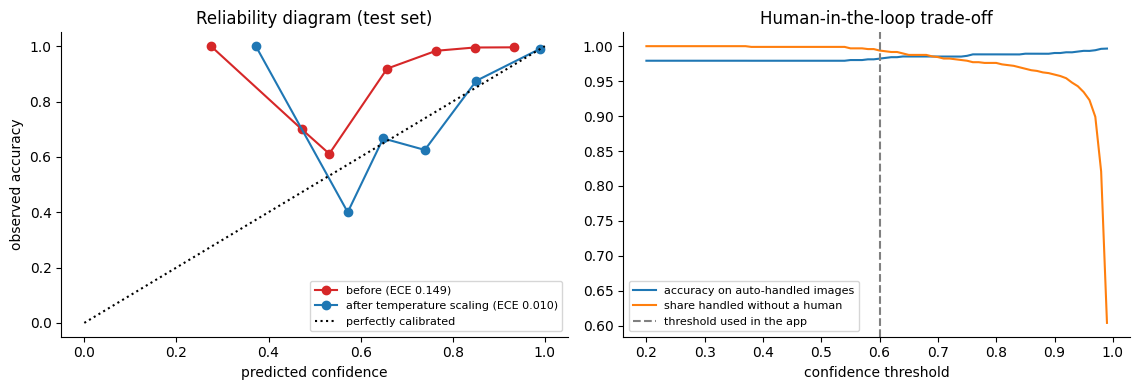

In [14]:
def fit_temperature(logits, y):
    grid = torch.logspace(math.log10(0.05), 1, 241)         # T between 0.05 and 10
    nll = torch.stack([F.cross_entropy(logits / t, y) for t in grid])
    return float(grid[nll.argmin()])


def ece(probs, y, n_bins=15):
    conf, pred = probs.max(1)
    correct = (pred == y).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.float().mean() * (conf[m].mean() - correct[m].mean()).abs()
    return float(total)


TEMP = fit_temperature(RESULTS[BEST]["val_logits"], y_val)
p_raw, p_cal = test_logits.softmax(1), (test_logits / TEMP).softmax(1)
conf, pred = p_cal.max(1)
auto = conf >= CFG["uncertainty_threshold"]
CALIB = dict(temperature=TEMP, ece_before=ece(p_raw, y_test), ece_after=ece(p_cal, y_test),
             threshold=CFG["uncertainty_threshold"], auto_handled_share=float(auto.float().mean()),
             accuracy_auto_handled=float((pred[auto] == y_test[auto]).float().mean()) if auto.any() else float("nan"),
             accuracy_all=float((pred == y_test).float().mean()))
print(f"Temperature T = {TEMP:.2f} | test ECE {CALIB['ece_before']:.3f} -> {CALIB['ece_after']:.3f}")
print(f"Threshold {CFG['uncertainty_threshold']:.2f}: {CALIB['auto_handled_share']:.1%} of test images are handled "
      f"automatically with {CALIB['accuracy_auto_handled']:.1%} accuracy (all images: {CALIB['accuracy_all']:.1%}); "
      f"the rest are sent to a human.")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
edges = np.linspace(0, 1, 11)
for label, P, col in [("before", p_raw, "#d62728"), ("after temperature scaling", p_cal, "#1f77b4")]:
    c, pr = P.max(1)
    ok = (pr == y_test).float()
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (c > lo) & (c <= hi)
        if m.sum() > 0:
            xs.append(float(c[m].mean()))
            ys.append(float(ok[m].mean()))
    axes[0].plot(xs, ys, "o-", color=col, label=f"{label} (ECE {ece(P, y_test):.3f})")
axes[0].plot([0, 1], [0, 1], "k:", label="perfectly calibrated")
axes[0].set(xlabel="predicted confidence", ylabel="observed accuracy", title="Reliability diagram (test set)")
axes[0].legend(fontsize=8)

ths = np.linspace(0.2, 0.99, 80)
coverage = [float((conf >= t).float().mean()) for t in ths]
accuracy = [float((pred[conf >= t] == y_test[conf >= t]).float().mean()) if (conf >= t).any() else np.nan
            for t in ths]
axes[1].plot(ths, accuracy, label="accuracy on auto-handled images")
axes[1].plot(ths, coverage, label="share handled without a human")
axes[1].axvline(CFG["uncertainty_threshold"], color="gray", ls="--", label="threshold used in the app")
axes[1].set(xlabel="confidence threshold", title="Human-in-the-loop trade-off")
axes[1].legend(fontsize=8)
save_fig("calibration.png")

## 9 · Grad-CAM: where is the model looking?

Grad-CAM (Selvaraju et al., 2017) weights the last convolutional feature maps by the gradient of the predicted class score. Red = regions that pushed the decision. Good models look at the flames, water or rubble — not at the sky, watermarks or image borders. The second figure shows the **mistakes**, which is where Grad-CAM is most useful for debugging.

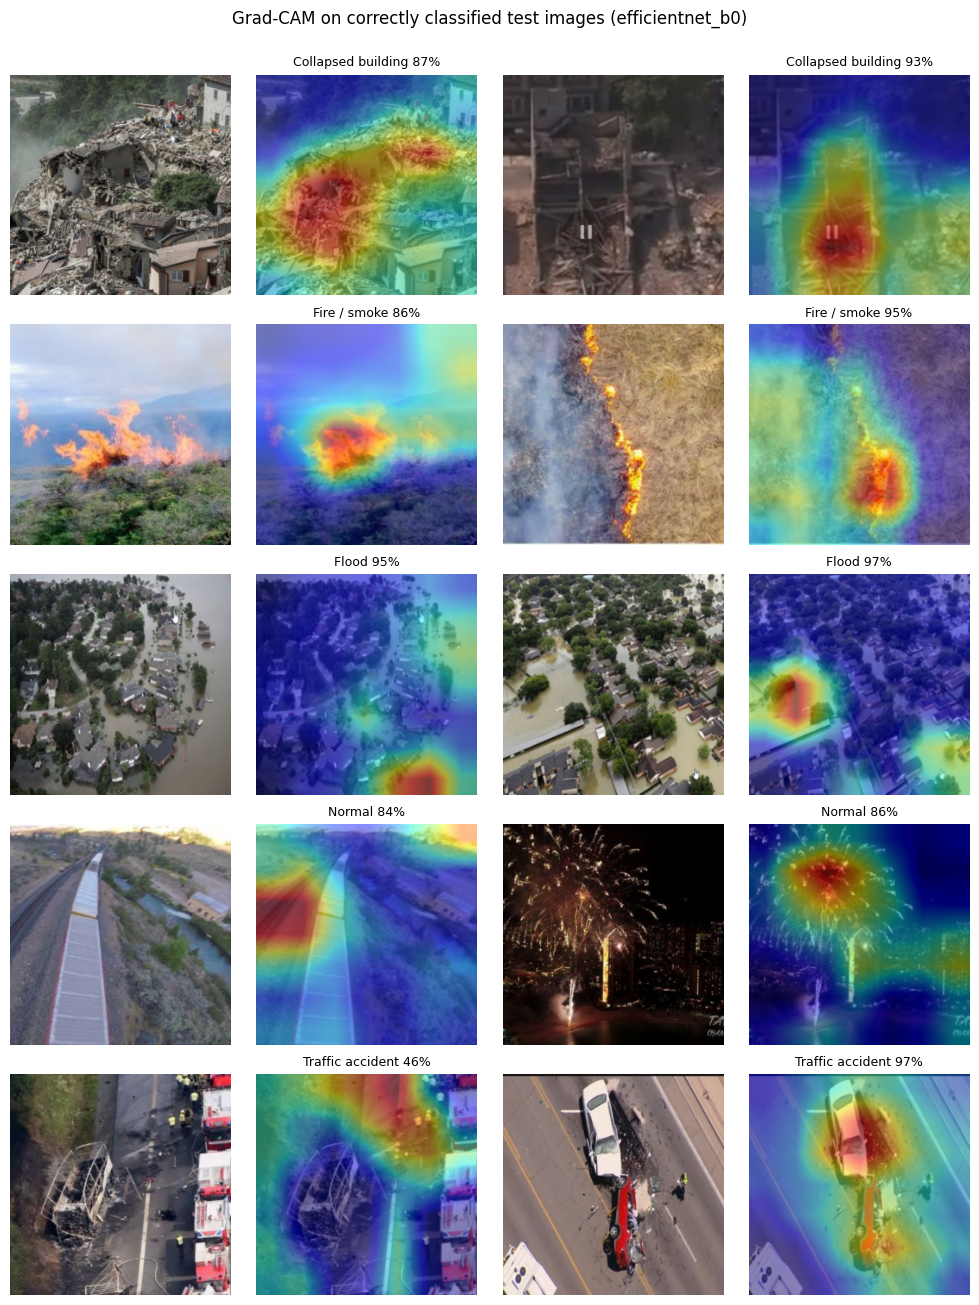

20 of 960 test images misclassified


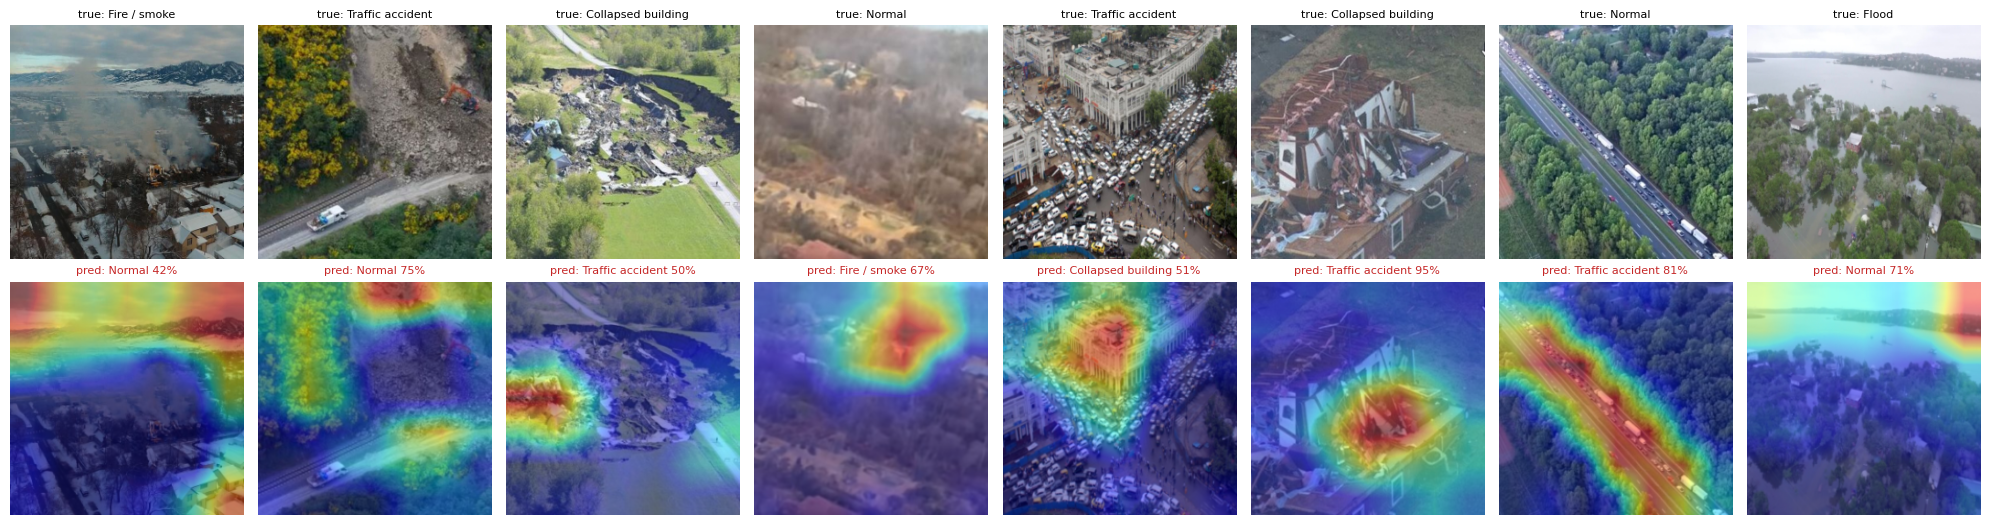

In [15]:
class GradCAM:
    """Grad-CAM on a chosen convolutional layer (hooks are attached only during the call)."""
    def __init__(self, model, layer):
        self.model, self.layer = model, layer

    def __call__(self, x, class_idx=None):
        store = {}

        def hook(_module, _inputs, out):
            store["act"] = out
            out.register_hook(lambda g: store.__setitem__("grad", g))

        handle = self.layer.register_forward_hook(hook)
        try:
            self.model.eval()
            self.model.zero_grad(set_to_none=True)
            with torch.enable_grad():
                logits = self.model(x.clone().requires_grad_(True))   # works even if layers are frozen
                class_idx = int(logits.argmax(1)) if class_idx is None else class_idx
                logits[0, class_idx].backward()
        finally:
            handle.remove()
        weights = store["grad"].mean(dim=(2, 3), keepdim=True)            # importance of each feature map
        cam = F.relu((weights * store["act"]).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), logits.detach().float().softmax(1)[0].cpu().numpy(), class_idx


def overlay(rgb, cam, alpha=0.45):
    heat = matplotlib.colormaps["jet"](cam)[..., :3]
    return np.clip((1 - alpha) * rgb / 255.0 + alpha * heat, 0, 1)


cam_engine = GradCAM(best_model, best_model.features[-1])


def cam_for(j):
    x = eval_tf(Image.fromarray(IMAGES[j])).unsqueeze(0).to(DEVICE)
    cam, probs, k = cam_engine(x)
    rgb = np.asarray(Image.fromarray(IMAGES[j]).resize((SZ, SZ), Image.Resampling.BILINEAR))
    return overlay(rgb, cam), probs, k


rng = np.random.default_rng(7)
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(10, 13))
for r, c in enumerate(CLASSES):
    correct = [j for j, p in zip(idx_test, test_pred) if LABELS[j] == r and p == r]
    for k, j in enumerate(rng.choice(correct, size=min(2, len(correct)), replace=False) if correct else []):
        ov, probs, _ = cam_for(j)
        axes[r, 2 * k].imshow(IMAGES[j])
        axes[r, 2 * k + 1].imshow(ov)
        axes[r, 2 * k + 1].set_title(f"{DISPLAY[c]} {probs[r]:.0%}", fontsize=9)
    for ax in axes[r]:
        ax.axis("off")
fig.suptitle(f"Grad-CAM on correctly classified test images ({BEST})", y=1.0)
save_fig("gradcam_correct.png")

wrong = [(j, int(LABELS[j]), int(p)) for j, p in zip(idx_test, test_pred) if LABELS[j] != p]
print(f"{len(wrong)} of {len(idx_test)} test images misclassified")
if wrong:
    n = min(8, len(wrong))
    fig, axes = plt.subplots(2, n, figsize=(2.5 * n, 5.4), squeeze=False)
    for k, (j, yt, yp) in enumerate(wrong[:n]):
        ov, probs, _ = cam_for(j)
        axes[0, k].imshow(IMAGES[j])
        axes[0, k].set_title(f"true: {DISPLAY[CLASSES[yt]]}", fontsize=8)
        axes[1, k].imshow(ov)
        axes[1, k].set_title(f"pred: {DISPLAY[CLASSES[yp]]} {probs[yp]:.0%}", fontsize=8, color="#c62828")
    for ax in axes.ravel():
        ax.axis("off")
    save_fig("gradcam_mistakes.png")

## 10 · Area-scan mode: from "what" to "where"

A real drone frame can cover a whole neighbourhood. Area scan cuts it into an *N × N* grid, classifies every tile in one batch and colours the tiles that show an emergency — a cheap way to turn an image classifier into a coarse **disaster map** without any bounding-box labels.
The demo below stitches four test photos into one large image, so we know the ground truth of each quadrant.

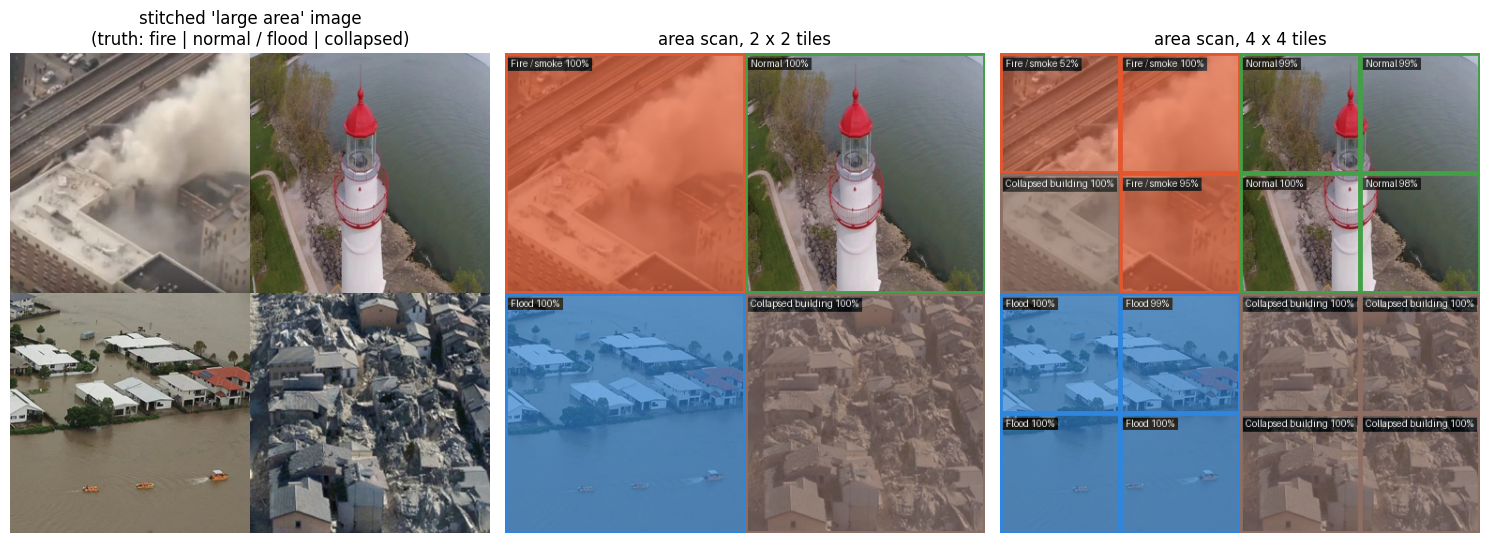

In [16]:
def tile_boxes(w, h, grid):
    return [(c * w // grid, r * h // grid, (c + 1) * w // grid, (r + 1) * h // grid)
            for r in range(grid) for c in range(grid)]


@torch.no_grad()
def scan_tiles(model, img, grid=3, temperature=1.0):
    boxes = tile_boxes(*img.size, grid)
    x = torch.stack([eval_tf(img.crop(b).resize((S, S), Image.Resampling.BILINEAR)) for b in boxes]).to(DEVICE)
    model.eval()
    return boxes, (model(x).float() / temperature).softmax(1).cpu().numpy()


def draw_scan(img, boxes, probs):
    base = img.convert("RGBA")
    layer = Image.new("RGBA", base.size, (0, 0, 0, 0))
    d = ImageDraw.Draw(layer)
    for b, p in zip(boxes, probs):
        k = int(p.argmax())
        c = CLASSES[k]
        rgb = tuple(int(CLASS_COLORS[c][i:i + 2], 16) for i in (1, 3, 5))
        if c != "normal":
            d.rectangle(b, fill=rgb + (int(60 + 100 * p[k]),))
        d.rectangle(b, outline=rgb + (255,), width=3)
        text = f"{DISPLAY[c]} {p[k]:.0%}"
        tb = d.textbbox((b[0] + 6, b[1] + 5), text)
        d.rectangle((tb[0] - 3, tb[1] - 2, tb[2] + 3, tb[3] + 2), fill=(0, 0, 0, 170))
        d.text((b[0] + 6, b[1] + 5), text, fill=(255, 255, 255, 255))
    return Image.alpha_composite(base, layer).convert("RGB")


test_probs = (test_logits / TEMP).softmax(1).numpy()


def most_confident_correct(class_name, k=1):
    r = CLASSES.index(class_name)
    pos = [i for i, j in enumerate(idx_test) if LABELS[j] == r and test_pred[i] == r]
    pos = sorted(pos, key=lambda i: -test_probs[i, r])[:k]
    return [int(idx_test[i]) for i in pos]


demo_classes = ["fire", "normal", "flooded_areas", "collapsed_building"]
picks = [(most_confident_correct(c) or [int(idx_test[0])])[0] for c in demo_classes]
mosaic = Image.new("RGB", (2 * S, 2 * S))
for k, j in enumerate(picks):
    mosaic.paste(Image.fromarray(IMAGES[j]), ((k % 2) * S, (k // 2) * S))

fig, axes = plt.subplots(1, 3, figsize=(15, 5.3))
axes[0].imshow(mosaic)
axes[0].set_title("stitched 'large area' image\n(truth: fire | normal / flood | collapsed)")
for ax, g in zip(axes[1:], (2, 4)):
    ax.imshow(draw_scan(mosaic, *scan_tiles(best_model, mosaic, grid=g, temperature=TEMP)))
    ax.set_title(f"area scan, {g} x {g} tiles")
for ax in axes:
    ax.axis("off")
save_fig("area_scan_demo.png")

## 11 · Edge readiness: size and CPU latency

A drone (or the laptop of a field team) usually has no big GPU, so we measure single-image latency on the CPU next to accuracy.

In [17]:
def cpu_latency_ms(model, runs=30):
    m = copy.deepcopy(model).float().cpu().eval().to(memory_format=torch.contiguous_format)
    x = torch.randn(1, 3, SZ, SZ)
    with torch.inference_mode():
        for _ in range(5):
            m(x)
        t0 = time.perf_counter()
        for _ in range(runs):
            m(x)
    return (time.perf_counter() - t0) / runs * 1000


def size_mb(model):
    buf = io.BytesIO()
    torch.save({k: v.cpu() for k, v in model.state_dict().items()}, buf)
    return buf.tell() / 1e6


rows = []
for arch, R in RESULTS.items():
    m = R["model"]
    rows.append({"model": arch, "params (M)": count_params(m), "size (MB)": size_mb(m),
                 f"CPU latency (ms, {torch.get_num_threads()} threads)": cpu_latency_ms(m),
                 "val macro-F1": R["best_val_f1"], "test accuracy": R["test"]["acc"],
                 "test macro-F1": R["test"]["macro_f1"], "test macro-F1 + TTA": R["test_tta"]["macro_f1"],
                 "train time (min)": R["train_minutes"]})
COMPARISON = pd.DataFrame(rows).round(4)
COMPARISON.to_csv(OUT_DIR / "model_comparison.csv", index=False)
print(COMPARISON.to_string(index=False))
try:
    print("\nMarkdown table for the README:\n\n" + COMPARISON.to_markdown(index=False))
except ImportError:
    pass

             model  params (M)  size (MB)  CPU latency (ms, 2 threads)  val macro-F1  test accuracy  test macro-F1  test macro-F1 + TTA  train time (min)
mobilenet_v3_large      4.2084    17.0232                      21.6501        0.9628         0.9792         0.9679               0.9640            3.2782
   efficientnet_b0      4.0140    16.3331                      29.2843        0.9685         0.9792         0.9611               0.9566            4.3553

Markdown table for the README:

| model              |   params (M) |   size (MB) |   CPU latency (ms, 2 threads) |   val macro-F1 |   test accuracy |   test macro-F1 |   test macro-F1 + TTA |   train time (min) |
|:-------------------|-------------:|------------:|------------------------------:|---------------:|----------------:|----------------:|----------------------:|-------------------:|
| mobilenet_v3_large |       4.2084 |     17.0232 |                       21.6501 |         0.9628 |          0.9792 |          0.9679 |     

## 12 · Export everything for the app and the report

`drishti_outputs.zip` (in the **Output** panel → `/kaggle/working`) contains:

* `drishti_model.pt` — weights + class names + preprocessing + calibration temperature (everything the app needs)
* `examples/` — sample images for the app (two per class + an area-scan mosaic)
* `figures/`, `metrics.json`, `model_comparison.csv`, `classification_report.txt`, `history_*.csv`, `splits.csv`

In [18]:
best_cpu = copy.deepcopy(best_model).float().cpu().eval().to(memory_format=torch.contiguous_format)
METRICS = {
    "selected_model": BEST,
    "test": {k: float(v) for k, v in RESULTS[BEST]["test"].items()},
    "test_tta": {k: float(v) for k, v in RESULTS[BEST]["test_tta"].items()},
    "per_class_recall": {c: float(REPORT[c]["recall"]) for c in CLASSES},
    "per_class_f1": {c: float(REPORT[c]["f1-score"]) for c in CLASSES},
    "calibration": {k: float(v) for k, v in CALIB.items()},
    "data": {"cleaning": CLEANING, "split_sizes": {s: int((df.split == s).sum()) for s in ("train", "val", "test")}},
}
checkpoint = {
    "arch": BEST,
    "state_dict": {k: v.contiguous() for k, v in best_cpu.state_dict().items()},
    "classes": CLASSES,
    "display_names": DISPLAY,
    "class_colors": CLASS_COLORS,
    "img_size": SZ,
    "cache_size": S,
    "mean": MEAN,
    "std": STD,
    "temperature": float(TEMP),
    "uncertainty_threshold": float(CFG["uncertainty_threshold"]),
    "metrics": METRICS,
    "dataset": "AIDER - Kyrkou & Theocharides (CVPRW 2019, IEEE JSTARS 2020), Zenodo DOI 10.5281/zenodo.3888300",
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "torch_version": str(torch.__version__),
}
MODEL_PATH = OUT_DIR / "drishti_model.pt"
torch.save(checkpoint, MODEL_PATH)

# reload exactly the way the app does (weights_only=True) and compare predictions
ck = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
check = build_model(ck["arch"], pretrained=False)
check.load_state_dict(ck["state_dict"])
check.eval()
xb = torch.stack([eval_tf(Image.fromarray(IMAGES[j])) for j in idx_test[:32]])
with torch.no_grad():
    same = bool((check(xb).argmax(1) == best_cpu(xb).argmax(1)).all())
print(f"Saved {MODEL_PATH.name} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB) - reload check passed: {same}")

# example images for the Gradio app: the 2 most confident correct test images per class (original files)
EX_DIR = OUT_DIR / "examples"
EX_DIR.mkdir(exist_ok=True)
for c in CLASSES:
    for n, j in enumerate(most_confident_correct(c, k=2), start=1):
        with Image.open(df.path.iloc[j]) as im:
            im = ImageOps.exif_transpose(im).convert("RGB")
            im.thumbnail((640, 640))
            im.save(EX_DIR / f"{c}_{n}.jpg", quality=90)
# higher-resolution mosaic for the app's "Area scan" tab
big = Image.new("RGB", (800, 800))
for k, j in enumerate(picks):
    with Image.open(df.path.iloc[j]) as im:
        big.paste(ImageOps.exif_transpose(im).convert("RGB").resize((400, 400), Image.Resampling.BILINEAR),
                  ((k % 2) * 400, (k // 2) * 400))
big.save(EX_DIR / "area_scan_demo.jpg", quality=90)

with open(OUT_DIR / "metrics.json", "w") as f:
    json.dump({"config": CFG, "comparison": COMPARISON.to_dict(orient="records"), **METRICS},
              f, indent=2, default=float)

archive = shutil.make_archive(str(WORK_DIR / "drishti_outputs"), "zip", OUT_DIR)
print(f"\n📦 {archive} ({Path(archive).stat().st_size / 1e6:.1f} MB) contains:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print("   ", p.relative_to(OUT_DIR))

Saved drishti_model.pt (16.3 MB) - reload check passed: True

📦 /kaggle/working/drishti_outputs.zip (27.9 MB) contains:
    classification_report.txt
    drishti_model.pt
    examples/area_scan_demo.jpg
    examples/collapsed_building_1.jpg
    examples/collapsed_building_2.jpg
    examples/fire_1.jpg
    examples/fire_2.jpg
    examples/flooded_areas_1.jpg
    examples/flooded_areas_2.jpg
    examples/normal_1.jpg
    examples/normal_2.jpg
    examples/traffic_incident_1.jpg
    examples/traffic_incident_2.jpg
    figures/area_scan_demo.png
    figures/augmentations.png
    figures/calibration.png
    figures/class_distribution.png
    figures/confusion_matrix.png
    figures/gradcam_correct.png
    figures/gradcam_mistakes.png
    figures/samples.png
    figures/training_curves.png
    history_efficientnet_b0.csv
    history_mobilenet_v3_large.csv
    metrics.json
    model_comparison.csv
    splits.csv


In [19]:
import shutil
shutil.make_archive("/kaggle/working/drishti_outputs","zip","/kaggle/working/drishti_outputs")

'/kaggle/working/drishti_outputs.zip'